# Практическая работа № 7. Случайный лес

ФИО: Эркинбеков Айман  
Вариант: B

Продолжаю работу с Titanic из ПР-2, ПР-3 и ПР-5. Предсказываю, выжил ли пассажир: в столбце `Survived` 1 означает «выжил». В ПР-5 я переворачивал цель, здесь оставляю как в файле.

Сравню одиночное дерево и случайный лес, подберу гиперпараметры леса через кросс-валидацию, посмотрю важность признаков и проверю, можно ли убрать слабые признаки без потери качества.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier

print("Библиотеки загружены")

Библиотеки загружены


## 1. Данные

Беру копию того же `train.csv`, что использовался в предыдущих работах. Источник: [Titanic на Kaggle](https://www.kaggle.com/datasets/amineipad/titanic-dataset).

In [2]:
DATA_PATH = Path("../data/train.csv")

if not DATA_PATH.exists():
    DATA_PATH = Path("practical-07/data/train.csv")

assert DATA_PATH.exists(), f"Файл не найден: {DATA_PATH}"

df = pd.read_csv(DATA_PATH)

NUM_FEATURES = ["Age", "SibSp", "Parch", "Fare", "Pclass"]
CAT_FEATURES = ["Sex", "Embarked"]
ALL_FEATURES = NUM_FEATURES + CAT_FEATURES

X = df[ALL_FEATURES].copy()
y = df["Survived"]

print("Размер таблицы:", df.shape)
print("Survived (0 = не выжил, 1 = выжил):")
display(y.value_counts().sort_index().to_frame("Количество"))
print("Пропуски в признаках:")
display(X.isna().sum().to_frame("Пропусков").T)

Размер таблицы: (891, 12)
Survived (0 = не выжил, 1 = выжил):


,Количество
Survived,
0,549
1,342


Пропуски в признаках:


,Age,SibSp,Parch,Fare,Pclass,Sex,Embarked
Пропусков,177,0,0,0,0,0,2


В таблице 891 строка. Не выжили 549 пассажиров, выжили 342. Пропуски есть в возрасте (177) и в порте посадки (2), их закрою в `Pipeline`.

## 2. Разбиение

Делю данные один раз: 80% на обучение и 20% на тест, `random_state=42`, с сохранением доли классов. Дерево и лес учатся на одной и той же обучающей части и проверяются на одном и том же тесте. Гиперпараметры подбираю только кросс-валидацией на обучающей части.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Обучение:", X_train.shape)
print("Тест:    ", X_test.shape)
print("Доля выживших в train:", round(y_train.mean(), 3))
print("Доля выживших в test: ", round(y_test.mean(), 3))

# Одна и та же схема кросс-валидации для всех сравнений ниже
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Обучение: (712, 7)
Тест:     (179, 7)
Доля выживших в train: 0.383
Доля выживших в test:  0.385


## 3. Предобработка

Деревьям масштабирование не нужно. Пропуски в числах заполняю медианой, в категориях значением `Unknown`. Пол и порт посадки кодирую числами через `OrdinalEncoder`. Тогда каждый признак остаётся одним столбцом, и важность можно читать по исходным названиям. Всё лежит в `Pipeline`, поэтому медианы и коды считаются только по обучающей части.

In [4]:
def build_pipeline(classifier, features):
    num = [f for f in NUM_FEATURES if f in features]
    cat = [f for f in CAT_FEATURES if f in features]

    transformers = []
    if num:
        transformers.append(("num", SimpleImputer(strategy="median"), num))
    if cat:
        cat_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
            ("ordinal", OrdinalEncoder(
                handle_unknown="use_encoded_value", unknown_value=-1
            )),
        ])
        transformers.append(("cat", cat_pipeline, cat))

    pipeline = Pipeline([
        ("preprocessor", ColumnTransformer(transformers)),
        ("classifier", classifier),
    ])
    return pipeline, num + cat   # второе значение: порядок столбцов после предобработки


def evaluate(model, X_part, y_part):
    pred = model.predict(X_part)
    proba = model.predict_proba(X_part)[:, 1]
    return {
        "Accuracy": accuracy_score(y_part, pred),
        "Precision": precision_score(y_part, pred),
        "Recall": recall_score(y_part, pred),
        "F1": f1_score(y_part, pred),
        "ROC-AUC": roc_auc_score(y_part, proba),
    }

print("Функции готовы")

Функции готовы


## 4. Одиночное дерево и случайный лес

Сначала сравниваю модели с параметрами по умолчанию: дерево без ограничения глубины и лес из 100 деревьев. Разбиение и предобработка у них одинаковые.

In [5]:
tree, _ = build_pipeline(DecisionTreeClassifier(random_state=42), ALL_FEATURES)
forest_default, _ = build_pipeline(
    RandomForestClassifier(n_estimators=100, random_state=42), ALL_FEATURES
)

tree.fit(X_train, y_train)
forest_default.fit(X_train, y_train)

rows = {}
for name, model in [("Дерево", tree), ("Лес (по умолчанию)", forest_default)]:
    train_metrics = evaluate(model, X_train, y_train)
    test_metrics = evaluate(model, X_test, y_test)
    rows[name] = {
        "Accuracy train": train_metrics["Accuracy"],
        "Accuracy test": test_metrics["Accuracy"],
        "F1 test": test_metrics["F1"],
        "ROC-AUC test": test_metrics["ROC-AUC"],
        "ROC-AUC CV": cross_val_score(
            model, X_train, y_train, cv=cv, scoring="roc_auc"
        ).mean(),
    }

display(pd.DataFrame(rows).T.round(3))
print("Глубина одиночного дерева:", tree.named_steps["classifier"].get_depth())

,Accuracy train,Accuracy test,F1 test,ROC-AUC test,ROC-AUC CV
Дерево,0.983,0.821,0.758,0.791,0.763
Лес (по умолчанию),0.983,0.804,0.737,0.831,0.869


Глубина одиночного дерева: 23


Одиночное дерево почти идеально запомнило обучающую часть: accuracy 0,983 при глубине 23, а на тесте 0,821. Это переобучение. На кросс-валидации ROC-AUC у дерева 0,763, у леса 0,869, на тесте 0,791 и 0,831.

Accuracy на тесте у дерева чуть выше (0,821 против 0,804), но тест маленький, 179 объектов, и разница около трёх объектов. Поэтому сравниваю по ROC-AUC, и по нему лес лучше.

## 5. Число деревьев

Чтобы выбрать число деревьев, смотрю на out-of-bag оценку. Каждое дерево учится на бутстрэп-выборке, а объекты, которые в неё не попали, служат для проверки. Тестовую часть здесь не использую.

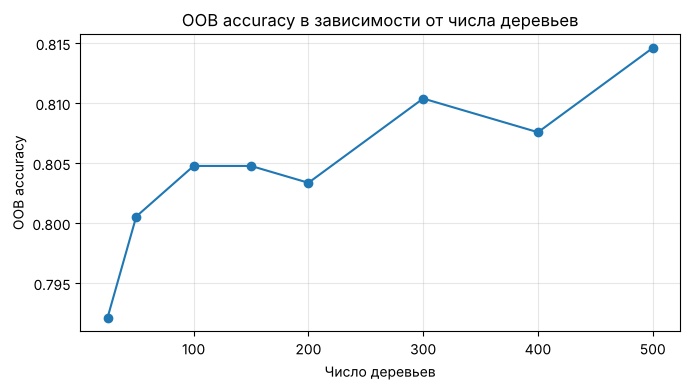

,Деревьев,OOB accuracy
0,25,0.7921
1,50,0.8006
2,100,0.8048
3,150,0.8048
4,200,0.8034
5,300,0.8104
6,400,0.8076
7,500,0.8146


In [6]:
pre, _ = build_pipeline(RandomForestClassifier(), ALL_FEATURES)
X_train_prepared = pre.named_steps["preprocessor"].fit_transform(X_train)

tree_counts = [25, 50, 100, 150, 200, 300, 400, 500]
oob_scores = []

for n in tree_counts:
    rf = RandomForestClassifier(
        n_estimators=n, oob_score=True, random_state=42, n_jobs=-1
    )
    rf.fit(X_train_prepared, y_train)
    oob_scores.append(rf.oob_score_)

plt.figure(figsize=(7, 4))
plt.plot(tree_counts, oob_scores, marker="o")
plt.title("OOB accuracy в зависимости от числа деревьев")
plt.xlabel("Число деревьев")
plt.ylabel("OOB accuracy")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(pd.DataFrame({"Деревьев": tree_counts, "OOB accuracy": np.round(oob_scores, 4)}))

OOB accuracy растёт примерно до 100 деревьев (с 0,792 до 0,805), дальше колеблется между 0,803 и 0,815. На 712 объектах такие колебания это шум. Беру 100 деревьев: этого хватает, а обучение быстрое. В подборе ниже сравниваю 100, 200 и 300 деревьев: больше 100 качество на кросс-валидации не растёт.

## 6. Подбор гиперпараметров

Перебираю `n_estimators`, `max_depth` и `min_samples_leaf` через `GridSearchCV` с 5-кратной кросс-валидацией на обучающей части. Оцениваю по ROC-AUC: классы не поровну, а AUC не зависит от порога.

In [7]:
base_pipeline, _ = build_pipeline(RandomForestClassifier(random_state=42), ALL_FEATURES)

param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [3, 5, 7, 10, None],
    "classifier__min_samples_leaf": [1, 2, 4, 8],
}

grid = GridSearchCV(
    base_pipeline,
    param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
)
grid.fit(X_train, y_train)

best_params = {k.replace("classifier__", ""): v for k, v in grid.best_params_.items()}
print("Лучшие параметры:", best_params)
print("ROC-AUC на кросс-валидации:", round(grid.best_score_, 4))

results = pd.DataFrame(grid.cv_results_)
top = results.sort_values("rank_test_score").head(8)[
    ["param_classifier__n_estimators", "param_classifier__max_depth",
     "param_classifier__min_samples_leaf", "mean_test_score", "std_test_score"]
]
top.columns = ["n_estimators", "max_depth", "min_samples_leaf", "ROC-AUC (CV)", "Разброс"]
display(top.round(4).reset_index(drop=True))

Лучшие параметры: {'max_depth': 10, 'min_samples_leaf': 4, 'n_estimators': 100}
ROC-AUC на кросс-валидации: 0.882


,n_estimators,max_depth,min_samples_leaf,ROC-AUC (CV),Разброс
0,100,10,4,0.8820,0.0186
1,100,None,4,0.8817,0.0206
2,300,None,4,0.8805,0.0200
3,200,None,4,0.8804,0.0195
4,200,10,4,0.8797,0.0193
5,300,10,4,0.8797,0.0195
6,100,5,4,0.8787,0.0215
7,100,7,4,0.8786,0.0195


In [8]:
default_cv = cross_val_score(
    forest_default, X_train, y_train, cv=cv, scoring="roc_auc"
)
print(f"Лес по умолчанию, ROC-AUC на CV: {default_cv.mean():.4f} (± {default_cv.std():.4f})")
print(f"Лес настроенный,  ROC-AUC на CV: {grid.best_score_:.4f}")

best_model = grid.best_estimator_

final = pd.DataFrame({
    "Дерево": evaluate(tree, X_test, y_test),
    "Лес (по умолчанию)": evaluate(forest_default, X_test, y_test),
    "Лес (настроенный)": evaluate(best_model, X_test, y_test),
}).T

print("\nМетрики на тестовой выборке:")
display(final.round(3))

Лес по умолчанию, ROC-AUC на CV: 0.8694 (± 0.0077)
Лес настроенный,  ROC-AUC на CV: 0.8820

Метрики на тестовой выборке:


,Accuracy,Precision,Recall,F1,ROC-AUC
Дерево,0.821,0.794,0.725,0.758,0.791
Лес (по умолчанию),0.804,0.766,0.710,0.737,0.831
Лес (настроенный),0.799,0.800,0.638,0.710,0.831


Лучшие параметры: `n_estimators=100`, `max_depth=10`, `min_samples_leaf=4`. На кросс-валидации ROC-AUC вырос с 0,869 до 0,882. На тесте ROC-AUC одинаковый (0,831), а accuracy 0,799 против 0,804: разница в один объект.

Получается, что на кросс-валидации настройка помогла немного, а на тесте выигрыш не подтвердился. Оценка 0,882 к тому же чуть завышена, потому что это лучший результат из 60 комбинаций. Настроенный лес стал осторожнее: precision выше (0,800 против 0,766), recall ниже (0,638 против 0,710). Параметр `min_samples_leaf=4` не даёт листьям запоминать единичные объекты, поэтому лес меньше переобучается.

## 7. Важность признаков

Беру встроенную важность `feature_importances_` у настроенного леса, обученного на обучающей части.

,Важность
Sex,0.395
Fare,0.223
Age,0.143
Pclass,0.123
Embarked,0.045
SibSp,0.041
Parch,0.031


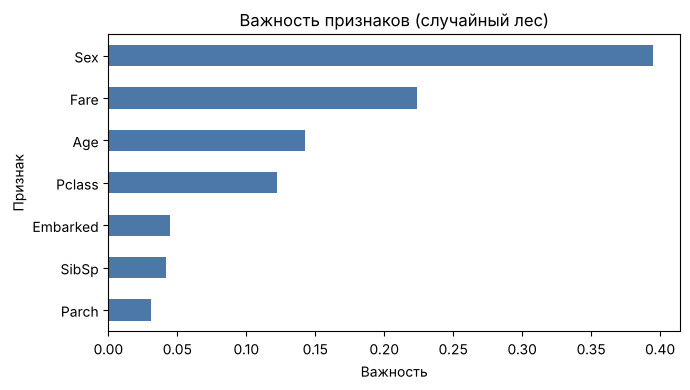

In [9]:
_, feature_names = build_pipeline(RandomForestClassifier(), ALL_FEATURES)

importances = best_model.named_steps["classifier"].feature_importances_
importance_table = (
    pd.Series(importances, index=feature_names)
    .sort_values(ascending=False)
    .to_frame("Важность")
)

display(importance_table.round(3))

plt.figure(figsize=(7, 4))
importance_table["Важность"][::-1].plot(kind="barh", color="#4C78A8")
plt.title("Важность признаков (случайный лес)")
plt.xlabel("Важность")
plt.ylabel("Признак")
plt.tight_layout()
plt.show()

Самые важные признаки: пол (0,395), стоимость билета (0,223), возраст (0,143) и класс (0,123). На остальные три приходится по 0,03–0,05.

Важность показывает, насколько признак помогает модели разделять классы, а не причину выживания, поэтому причинно-следственный вывод делать нельзя. Встроенная важность ещё завышает признаки с большим числом разных значений (Age и Fare), а Fare и Pclass связаны между собой, поэтому важность между ними делится.

## 8. Удаление слабых признаков

Убираю признаки по одному, начиная с самого слабого, и каждый раз заново оцениваю лес с найденными параметрами. Порядок признаков взят по обучающей части. Решение принимаю по кросс-валидации, тест показываю для контроля.

,Признаков,Убран на этом шаге,ROC-AUC (CV),Разброс CV,ROC-AUC (тест),Accuracy (тест)
0,7,-,0.8820,0.0186,0.8314,0.7989
1,6,Parch,0.8793,0.0153,0.8357,0.8045
2,5,SibSp,0.8766,0.0166,0.8264,0.7877
3,4,Embarked,0.8700,0.0131,0.8216,0.7989
4,3,Pclass,0.8587,0.0206,0.7968,0.7821
5,2,Age,0.8368,0.0297,0.7970,0.7765
6,1,Fare,0.7704,0.0253,0.7534,0.7765


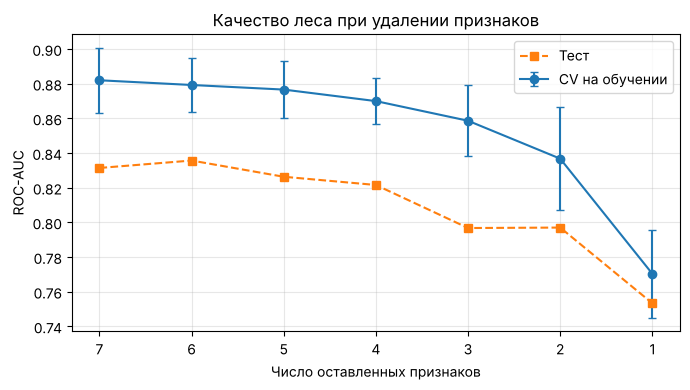

In [10]:
ranking = list(importance_table.index)

experiment = []
for k in range(len(ranking), 0, -1):
    kept = ranking[:k]
    model_k, _ = build_pipeline(
        RandomForestClassifier(**best_params, random_state=42, n_jobs=-1), kept
    )
    cv_scores = cross_val_score(model_k, X_train, y_train, cv=cv, scoring="roc_auc")
    model_k.fit(X_train, y_train)
    test_metrics = evaluate(model_k, X_test, y_test)

    experiment.append({
        "Признаков": k,
        "Убран на этом шаге": ranking[k] if k < len(ranking) else "-",
        "ROC-AUC (CV)": cv_scores.mean(),
        "Разброс CV": cv_scores.std(),
        "ROC-AUC (тест)": test_metrics["ROC-AUC"],
        "Accuracy (тест)": test_metrics["Accuracy"],
    })

experiment = pd.DataFrame(experiment)
display(experiment.round(4))

plt.figure(figsize=(7, 4))
plt.errorbar(experiment["Признаков"], experiment["ROC-AUC (CV)"],
             yerr=experiment["Разброс CV"], marker="o", capsize=3, label="CV на обучении")
plt.plot(experiment["Признаков"], experiment["ROC-AUC (тест)"],
         marker="s", linestyle="--", label="Тест")
plt.title("Качество леса при удалении признаков")
plt.xlabel("Число оставленных признаков")
plt.ylabel("ROC-AUC")
plt.gca().invert_xaxis()
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

ROC-AUC на кросс-валидации при удалении признаков: 0,882 со всеми семью, 0,879 без Parch, 0,877 без Parch и SibSp, 0,870 без ещё и Embarked, 0,859 без Pclass. Дальше качество падает резко: 0,837 с двумя признаками и 0,770 только с Fare.

Разброс между фолдами 0,013–0,021, поэтому потеря в 0,005 это меньше обычного шума. Parch и SibSp можно убрать без потери качества: на кросс-валидации минус 0,005, на тесте ROC-AUC 0,826 против 0,831. Embarked пограничный случай: на кросс-валидации минус 0,012, на тесте минус 0,010, поэтому я бы его оставил. Pclass, Age и Fare убирать нельзя, качество заметно падает.

## Итог

Дерево без ограничений переобучилось: accuracy 0,983 на обучении и 0,821 на тесте, ROC-AUC на кросс-валидации 0,763. Лес из 100 деревьев на кросс-валидации лучше: 0,869, а на тесте ROC-AUC 0,831 против 0,791. Число деревьев 100 выбрал по OOB-оценке и по подбору. После `GridSearchCV` (`max_depth=10`, `min_samples_leaf=4`) ROC-AUC на кросс-валидации 0,882, на тесте остался 0,831. Самые важные признаки: Sex, Fare, Age, Pclass. Parch и SibSp можно исключить без потери качества.